<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/Praktikum_3_Machine_Learning_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Machine Learning: Data Preparation
Imputasi Missing Value, Outlier, dan Imbalanced Data (KNN Imputer, Isolation Forest, SMOTE, Undersampling, class_weight)



## 3.9 Implementasi Python
### Praktikum 3.1 Persiapan Library

In [1]:
!pip install -q imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, classification_report

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

print("Library siap dipakai")

Library siap dipakai


### Praktikum 3.2 Import Dataset
Dataset simulasi untuk klasifikasi (tidak seimbang: kelas 0 = 90%, kelas 1 = 10%).

In [3]:
X, y = make_classification(
    n_samples=2000, n_features=8, n_informative=5, n_redundant=1,
    weights=[0.9, 0.1], flip_y=0.01, class_sep=1.2, random_state=42
)
df = pd.DataFrame(X, columns=[f"fitur_{i+1}" for i in range(8)])
df["target"] = y

print("Ukuran data:", df.shape)
print("\nDistribusi kelas:")
print(df["target"].value_counts())
df.head()

Ukuran data: (2000, 9)

Distribusi kelas:
target
0    1798
1     202
Name: count, dtype: int64


,fitur_1,fitur_2,fitur_3,fitur_4,fitur_5,fitur_6,fitur_7,fitur_8,target
0,0.050667,-1.168981,0.265336,-1.089740,1.665084,-1.811640,1.413451,-2.717048,0
1,-1.715130,-1.487374,0.424416,0.423037,0.027095,0.087205,1.132119,-0.385314,0
2,1.591715,-0.415091,1.867147,-0.867061,0.421375,0.705149,1.029473,-0.467085,0
3,-0.636013,-1.473207,0.313984,-0.953360,0.442138,0.351961,0.000580,0.540189,0
4,-2.134029,0.773877,1.580522,-0.652769,-0.314780,0.841041,1.024301,1.531539,0


**Simulasi missing value** (5% data dihilangkan secara acak):

In [4]:
rng = np.random.default_rng(42)
fitur_cols = [c for c in df.columns if c.startswith("fitur")]

mask = rng.random(df[fitur_cols].shape) < 0.05
df_missing = df.copy()
df_missing[fitur_cols] = df_missing[fitur_cols].mask(mask)

print("Jumlah missing value per kolom:")
print(df_missing.isnull().sum())
print("\nProporsi missing (%):")
print((df_missing.isnull().mean() * 100).round(2))

Jumlah missing value per kolom:
fitur_1    101
fitur_2    107
fitur_3    112
fitur_4     88
fitur_5     89
fitur_6    100
fitur_7    101
fitur_8     90
target       0
dtype: int64

Proporsi missing (%):
fitur_1    5.05
fitur_2    5.35
fitur_3    5.60
fitur_4    4.40
fitur_5    4.45
fitur_6    5.00
fitur_7    5.05
fitur_8    4.50
target     0.00
dtype: float64


### Praktikum 3.3 Preprocessing
Imputasi dengan KNN Imputer, lalu deteksi outlier dengan Isolation Forest.

In [5]:
imputer = KNNImputer(n_neighbors=5)
df_imputed = df_missing.copy()
df_imputed[fitur_cols] = imputer.fit_transform(df_missing[fitur_cols])
print("Missing value setelah imputasi:", df_imputed[fitur_cols].isnull().sum().sum())

# Deteksi outlier dengan Isolation Forest
iso = IsolationForest(contamination=0.02, random_state=42)
df_imputed["is_outlier"] = iso.fit_predict(df_imputed[fitur_cols])
print("Jumlah outlier terdeteksi:", (df_imputed["is_outlier"] == -1).sum())

Missing value setelah imputasi: 0
Jumlah outlier terdeteksi: 40


**Contoh perhitungan IQR (3.8)** untuk data usia `[22, 24, 25, 27, 29, 30, 31, 95]`:

In [6]:
usia = np.array([22, 24, 25, 27, 29, 30, 31, 95])
Q1, Q3 = np.percentile(usia, 25), np.percentile(usia, 75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR
batas_bawah = Q1 - 1.5 * IQR

print(f"Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}")
print(f"Batas bawah = {batas_bawah}, Batas atas = {batas_atas}")
print("Outlier:", usia[(usia < batas_bawah) | (usia > batas_atas)])

Q1 = 24.75, Q3 = 30.25, IQR = 5.5
Batas bawah = 16.5, Batas atas = 38.5
Outlier: [95]


Nilai **95** > batas atas (38.875), jadi 95 termasuk outlier berdasarkan metode IQR.

---
## 3.10 Latihan Praktikum
### Praktikum 1: Perbandingan Strategi Imputasi
**Tujuan:** membandingkan dampak strategi imputasi terhadap performa model.

**Instruksi:** dataset dengan missing value, bandingkan performa model (Logistic Regression) antara (a) mean imputation dan (b) KNN Imputer, dihitung dengan mean F1-score.

Catatan: imputer dimasukkan ke dalam `Pipeline` supaya hanya belajar dari data train (mencegah data leakage). Hasil dirata-rata dengan 5-fold cross validation.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Dataset khusus Praktikum 1: kelas seimbang supaya F1 mencerminkan efek imputasi
Xb, yb = make_classification(n_samples=2000, n_features=8, n_informative=5, n_redundant=1,
                             weights=[0.5, 0.5], class_sep=0.8, random_state=42)
df_b = pd.DataFrame(Xb, columns=fitur_cols)
df_b["target"] = yb

rng = np.random.default_rng(42)
mask_b = rng.random(df_b[fitur_cols].shape) < 0.05
df_b_missing = df_b.copy()
df_b_missing[fitur_cols] = df_b_missing[fitur_cols].mask(mask_b)

X_miss = df_b_missing[fitur_cols]
y_miss = df_b_missing["target"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def buat_pipeline(imputer):
    return Pipeline([
        ("imputer", imputer),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000)),
    ])

strategi = {
    "Mean Imputation": SimpleImputer(strategy="mean"),
    "KNN Imputer (k=5)": KNNImputer(n_neighbors=5),
}

hasil_imp = []
for nama, imp in strategi.items():
    skor = cross_val_score(buat_pipeline(imp), X_miss, y_miss, cv=skf, scoring="f1")
    hasil_imp.append({"Strategi": nama, "Mean F1": skor.mean(), "Std F1": skor.std()})

tabel_imp = pd.DataFrame(hasil_imp).round(4)
tabel_imp

,Strategi,Mean F1,Std F1
0,Mean Imputation,0.7452,0.0080
1,KNN Imputer (k=5),0.7476,0.0105


**Tambahan:** pengaruh persentase missing value (5%, 20%, 40%).

Strategi,KNN Imputer (k=5),Mean Imputation
Missing,,
20%,0.7206,0.7116
40%,0.6809,0.6829
5%,0.7476,0.7452


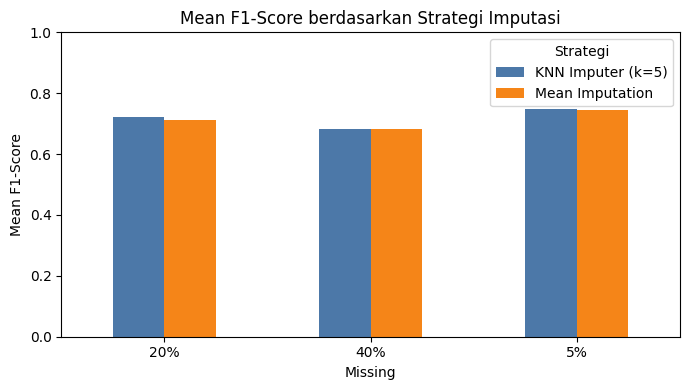

In [8]:
rates = [0.05, 0.20, 0.40]
rows = []
for r in rates:
    rng = np.random.default_rng(42)
    m = rng.random(df_b[fitur_cols].shape) < r
    Xr = df_b[fitur_cols].mask(m)
    for nama, imp in strategi.items():
        s = cross_val_score(buat_pipeline(imp), Xr, df_b["target"], cv=skf, scoring="f1")
        rows.append({"Missing": f"{int(r*100)}%", "Strategi": nama, "Mean F1": s.mean()})

tabel_rate = pd.DataFrame(rows).pivot(index="Missing", columns="Strategi", values="Mean F1").round(4)
display(tabel_rate)

tabel_rate.plot(kind="bar", figsize=(7,4), color=["#4C78A8", "#F58518"])
plt.title("Mean F1-Score berdasarkan Strategi Imputasi")
plt.ylabel("Mean F1-Score"); plt.xticks(rotation=0); plt.ylim(0, 1)
plt.tight_layout(); plt.show()

In [10]:
terbaik = tabel_imp.sort_values("Mean F1", ascending=False).iloc[0]
selisih = tabel_imp["Mean F1"].max() - tabel_imp["Mean F1"].min()
print(f"Strategi terbaik (missing 5%): {terbaik['Strategi']} dengan Mean F1 = {terbaik['Mean F1']:.4f}")
print(f"Selisih F1 antar strategi: {selisih:.4f}")

Strategi terbaik (missing 5%): KNN Imputer (k=5) dengan Mean F1 = 0.7476
Selisih F1 antar strategi: 0.0024


**Kesimpulan Praktikum 1**

Tulis hasil sesuai output di atas. Contoh kerangka:
- Pada missing value 5%, selisih F1 antara mean imputation dan KNN Imputer relatif kecil, karena data yang hilang sedikit.
- KNN Imputer memanfaatkan korelasi antar fitur sehingga cenderung lebih baik saat missing value makin banyak, tetapi lebih lambat secara komputasi pada dataset besar.
- Mean imputation sederhana dan cepat, tapi bisa mengurangi variasi data.

---
### Praktikum 2: Efektivitas Pendekatan Imbalanced Data
**Tujuan:** mengukur efektivitas SMOTE, undersampling, dan class_weight pada dataset yang sama.

Penting: SMOTE/undersampling **hanya diterapkan pada train set**, tidak pada test set, supaya tidak terjadi data leakage.

In [11]:
X_all = df[fitur_cols]
y_all = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=42
)
print("Distribusi train:", y_train.value_counts().to_dict())
print("Distribusi test :", y_test.value_counts().to_dict())

Distribusi train: {0: 1438, 1: 162}
Distribusi test : {0: 360, 1: 40}


In [12]:
# 1. Baseline (tanpa penanganan imbalance)
model_base = LogisticRegression(max_iter=1000).fit(X_train, y_train)

# 2. SMOTE (hanya pada train set)
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
model_sm = LogisticRegression(max_iter=1000).fit(X_sm, y_sm)

# 3. Undersampling (hanya pada train set)
X_rus, y_rus = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
model_rus = LogisticRegression(max_iter=1000).fit(X_rus, y_rus)

# 4. class_weight = "balanced"
model_cw = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train, y_train)

print("Distribusi setelah SMOTE         :", pd.Series(y_sm).value_counts().to_dict())
print("Distribusi setelah undersampling :", pd.Series(y_rus).value_counts().to_dict())

Distribusi setelah SMOTE         : {0: 1438, 1: 1438}
Distribusi setelah undersampling : {0: 162, 1: 162}


### Evaluasi

In [13]:
models = {
    "Baseline": model_base,
    "SMOTE": model_sm,
    "Undersampling": model_rus,
    "class_weight": model_cw,
}

rows = []
for nama, m in models.items():
    pred = m.predict(X_test)
    rows.append({
        "Pendekatan": nama,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
    })

tabel_eval = pd.DataFrame(rows).set_index("Pendekatan").round(4)
tabel_eval

,Accuracy,Precision,Recall,F1-Score
Pendekatan,,,,
Baseline,0.9000,0.5000,0.150,0.2308
SMOTE,0.8050,0.3241,0.875,0.4730
Undersampling,0.7875,0.3043,0.875,0.4516
class_weight,0.7875,0.3043,0.875,0.4516


In [17]:
# Ambil hanya sampel sintetis dari hasil SMOTE
n_asli = len(X_train)

X_sintetis = X_sm.iloc[n_asli:]
y_sintetis = y_sm.iloc[n_asli:]

print("Jumlah sampel sintetis:", len(X_sintetis))
print("Kelas sampel sintetis :", y_sintetis.unique())   # semuanya kelas 1 (minoritas)

X_sintetis.head(10)

Jumlah sampel sintetis: 1276
Kelas sampel sintetis : [1]


,fitur_1,fitur_2,fitur_3,fitur_4,fitur_5,fitur_6,fitur_7,fitur_8
1600,1.291195,-0.907021,-0.285562,-0.258022,0.170152,1.148648,-1.447612,1.300363
1601,-0.996824,-0.628046,-0.484006,-2.854022,2.192492,-0.584056,-0.245307,-0.577289
1602,-0.785074,0.762004,-0.787573,-0.953169,0.269251,-0.047583,-1.297199,1.477888
1603,1.442615,-0.928287,1.078058,1.211872,-1.018910,-0.373302,-0.486575,1.830267
1604,-2.707443,1.091517,-3.126261,-1.795230,1.280959,-0.247769,-2.941147,1.977377
1605,-0.719174,0.338208,-0.402115,-1.770655,1.092410,0.212751,0.344697,-1.201060
1606,0.252536,-0.155451,3.063915,1.675036,-1.592750,-0.107987,2.322404,0.478444
1607,-0.681440,-2.097468,-0.577819,-1.391887,1.895196,-0.112538,-1.372849,1.281205
1608,0.150338,-0.682530,0.260494,0.615976,1.783047,0.685078,0.891214,-1.761328
1609,1.229908,-0.103229,0.143260,-0.127337,-0.372288,0.654201,-0.514521,0.469207


In [18]:
df_smote = X_sm.copy()
df_smote["target"] = y_sm.values
df_smote["jenis"] = ["asli"] * n_asli + ["sintetis"] * (len(X_sm) - n_asli)

df_smote[df_smote["jenis"] == "sintetis"].head(10)

,fitur_1,fitur_2,fitur_3,fitur_4,fitur_5,fitur_6,fitur_7,fitur_8,target,jenis
1600,1.291195,-0.907021,-0.285562,-0.258022,0.170152,1.148648,-1.447612,1.300363,1,sintetis
1601,-0.996824,-0.628046,-0.484006,-2.854022,2.192492,-0.584056,-0.245307,-0.577289,1,sintetis
1602,-0.785074,0.762004,-0.787573,-0.953169,0.269251,-0.047583,-1.297199,1.477888,1,sintetis
1603,1.442615,-0.928287,1.078058,1.211872,-1.018910,-0.373302,-0.486575,1.830267,1,sintetis
1604,-2.707443,1.091517,-3.126261,-1.795230,1.280959,-0.247769,-2.941147,1.977377,1,sintetis
1605,-0.719174,0.338208,-0.402115,-1.770655,1.092410,0.212751,0.344697,-1.201060,1,sintetis
1606,0.252536,-0.155451,3.063915,1.675036,-1.592750,-0.107987,2.322404,0.478444,1,sintetis
1607,-0.681440,-2.097468,-0.577819,-1.391887,1.895196,-0.112538,-1.372849,1.281205,1,sintetis
1608,0.150338,-0.682530,0.260494,0.615976,1.783047,0.685078,0.891214,-1.761328,1,sintetis
1609,1.229908,-0.103229,0.143260,-0.127337,-0.372288,0.654201,-0.514521,0.469207,1,sintetis


In [19]:
df_smote = X_sm.copy()
df_smote["target"] = y_sm.values
df_smote["jenis"] = ["asli"] * n_asli + ["sintetis"] * (len(X_sm) - n_asli)

df_smote[df_smote["jenis"] == "sintetis"].head(10)

,fitur_1,fitur_2,fitur_3,fitur_4,fitur_5,fitur_6,fitur_7,fitur_8,target,jenis
1600,1.291195,-0.907021,-0.285562,-0.258022,0.170152,1.148648,-1.447612,1.300363,1,sintetis
1601,-0.996824,-0.628046,-0.484006,-2.854022,2.192492,-0.584056,-0.245307,-0.577289,1,sintetis
1602,-0.785074,0.762004,-0.787573,-0.953169,0.269251,-0.047583,-1.297199,1.477888,1,sintetis
1603,1.442615,-0.928287,1.078058,1.211872,-1.018910,-0.373302,-0.486575,1.830267,1,sintetis
1604,-2.707443,1.091517,-3.126261,-1.795230,1.280959,-0.247769,-2.941147,1.977377,1,sintetis
1605,-0.719174,0.338208,-0.402115,-1.770655,1.092410,0.212751,0.344697,-1.201060,1,sintetis
1606,0.252536,-0.155451,3.063915,1.675036,-1.592750,-0.107987,2.322404,0.478444,1,sintetis
1607,-0.681440,-2.097468,-0.577819,-1.391887,1.895196,-0.112538,-1.372849,1.281205,1,sintetis
1608,0.150338,-0.682530,0.260494,0.615976,1.783047,0.685078,0.891214,-1.761328,1,sintetis
1609,1.229908,-0.103229,0.143260,-0.127337,-0.372288,0.654201,-0.514521,0.469207,1,sintetis


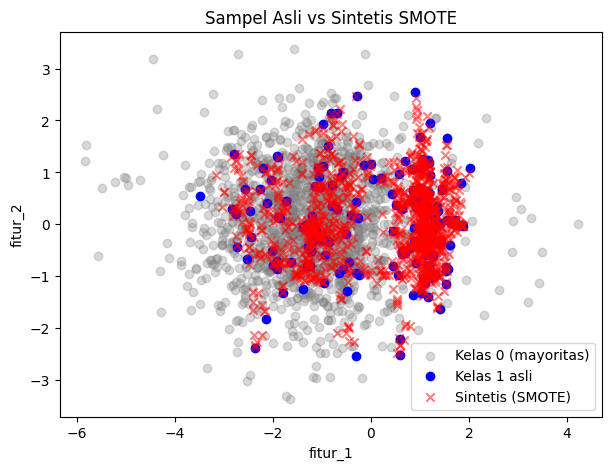

In [20]:
asli_min = X_train[y_train == 1]

plt.figure(figsize=(7, 5))
plt.scatter(X_train[y_train == 0]["fitur_1"], X_train[y_train == 0]["fitur_2"],
            alpha=0.3, label="Kelas 0 (mayoritas)", color="gray")
plt.scatter(asli_min["fitur_1"], asli_min["fitur_2"],
            label="Kelas 1 asli", color="blue")
plt.scatter(X_sintetis["fitur_1"], X_sintetis["fitur_2"],
            alpha=0.5, label="Sintetis (SMOTE)", color="red", marker="x")
plt.xlabel("fitur_1"); plt.ylabel("fitur_2")
plt.title("Sampel Asli vs Sintetis SMOTE")
plt.legend(); plt.show()

In [14]:
for nama, m in models.items():
    print(f"=== {nama} ===")
    print(classification_report(y_test, m.predict(X_test), zero_division=0))

=== Baseline ===
              precision    recall  f1-score   support

           0       0.91      0.98      0.95       360
           1       0.50      0.15      0.23        40

    accuracy                           0.90       400
   macro avg       0.71      0.57      0.59       400
weighted avg       0.87      0.90      0.87       400

=== SMOTE ===
              precision    recall  f1-score   support

           0       0.98      0.80      0.88       360
           1       0.32      0.88      0.47        40

    accuracy                           0.81       400
   macro avg       0.65      0.84      0.68       400
weighted avg       0.92      0.81      0.84       400

=== Undersampling ===
              precision    recall  f1-score   support

           0       0.98      0.78      0.87       360
           1       0.30      0.88      0.45        40

    accuracy                           0.79       400
   macro avg       0.64      0.83      0.66       400
weighted avg       0.

### Visualisasi

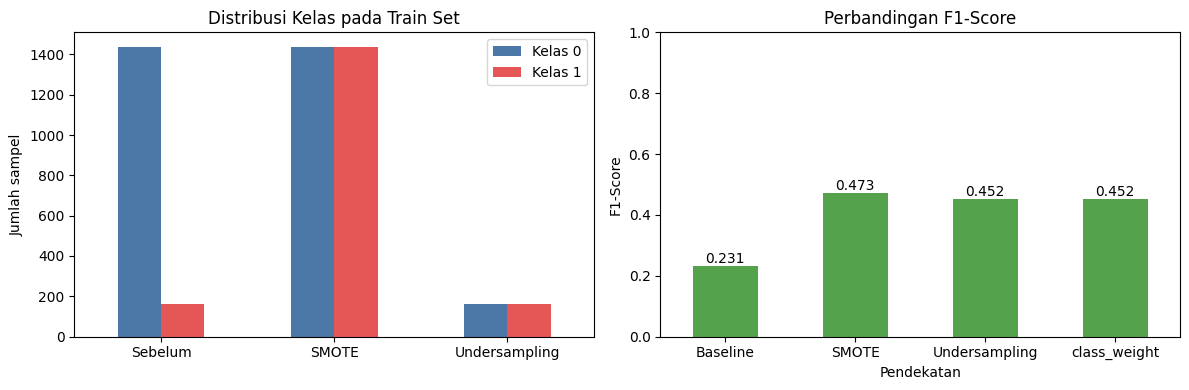

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribusi kelas sebelum dan sesudah
dist = pd.DataFrame({
    "Sebelum": y_train.value_counts().sort_index(),
    "SMOTE": pd.Series(y_sm).value_counts().sort_index(),
    "Undersampling": pd.Series(y_rus).value_counts().sort_index(),
})
dist.T.plot(kind="bar", ax=axes[0], color=["#4C78A8", "#E45756"])
axes[0].set_title("Distribusi Kelas pada Train Set")
axes[0].set_ylabel("Jumlah sampel"); axes[0].legend(["Kelas 0", "Kelas 1"])
axes[0].tick_params(axis="x", rotation=0)

# Perbandingan F1-Score
tabel_eval["F1-Score"].plot(kind="bar", ax=axes[1], color="#54A24B")
axes[1].set_title("Perbandingan F1-Score")
axes[1].set_ylabel("F1-Score"); axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(tabel_eval["F1-Score"]):
    axes[1].text(i, v + 0.01, f"{v:.3f}", ha="center")

plt.tight_layout(); plt.show()

### Interpretasi dan Kesimpulan

In [16]:
terbaik = tabel_eval["F1-Score"].idxmax()
print("Pendekatan dengan F1-Score tertinggi:", terbaik)
print(f"F1-Score: {tabel_eval.loc[terbaik, 'F1-Score']:.4f}")
print(f"F1-Score baseline: {tabel_eval.loc['Baseline', 'F1-Score']:.4f}")
print("\nRecall kelas minoritas per pendekatan:")
print(tabel_eval["Recall"])

Pendekatan dengan F1-Score tertinggi: SMOTE
F1-Score: 0.4730
F1-Score baseline: 0.2308

Recall kelas minoritas per pendekatan:
Pendekatan
Baseline         0.150
SMOTE            0.875
Undersampling    0.875
class_weight     0.875
Name: Recall, dtype: float64


**Kesimpulan Praktikum 2**

- Baseline punya akurasi tinggi (0,90), tapi recall kelas minoritas cuma 0,15 dan F1-nya 0,23, jadi akurasi menyesatkan pada data tidak seimbang.
- SMOTE, undersampling, dan class_weight sama-sama menaikkan recall kelas minoritas jadi 0,875 dan F1 naik hampir dua kali lipat.
- SMOTE paling efektif untuk kasus ini dengan F1 tertinggi (0,47), dibanding undersampling dan class_weight (0,45).
- Walau begitu, precision masih rendah (sekitar 0,3), karena sampel sintetis SMOTE bisa tumpang tindih dengan kelas mayoritas.